In [2]:
Experiment 6: PCA and Clustering Models

In [ ]:
Subtask 1.1: Data Acquisition and Feature Standardization

In [117]:
import warnings

In [3]:
warnings.filterwarnings("ignore")

In [4]:
import pandas as pd

In [5]:
import numpy as np

In [6]:
from sklearn.datasets import load_iris

In [7]:
from sklearn.preprocessing import StandardScaler

In [8]:
raw_iris = load_iris()

In [9]:
features = raw_iris.feature_names

In [10]:
X_raw = raw_iris.data

In [11]:
y_true = raw_iris.target

In [12]:
scaler = StandardScaler()

In [13]:
X_scaled = scaler.fit_transform(X_raw)

In [14]:
iris_df = pd.DataFrame(data=X_scaled, columns=features)

In [15]:
iris_df['species_id'] = y_true

In [16]:
species_map = {i: name for i, name in enumerate(raw_iris.target_names)}

In [17]:
iris_df['species_name'] = iris_df['species_id'].map(species_map)


In [18]:
print("Standardized dataset dimensions:", X_scaled.shape)

Standardized dataset dimensions: (150, 4)


In [19]:
print("\nFirst 3 rows of standardized dataset:")


First 3 rows of standardized dataset:


In [20]:
print(iris_df.head(3))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0          -0.900681          1.019004          -1.340227         -1.315444   
1          -1.143017         -0.131979          -1.340227         -1.315444   
2          -1.385353          0.328414          -1.397064         -1.315444   

   species_id species_name  
0           0       setosa  
1           0       setosa  
2           0       setosa  


In [ ]:
Subtask 1.2: Covariance Matrix and Eigenvalue Decomposition

In [22]:
cov_matrix = np.cov(X_scaled.T)

In [23]:
print("Covariance Matrix:\n", cov_matrix)

Covariance Matrix:
 [[ 1.00671141 -0.11835884  0.87760447  0.82343066]
 [-0.11835884  1.00671141 -0.43131554 -0.36858315]
 [ 0.87760447 -0.43131554  1.00671141  0.96932762]
 [ 0.82343066 -0.36858315  0.96932762  1.00671141]]


In [24]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

In [25]:
print("\nEigenvalues (Variance components):\n", eigenvalues)


Eigenvalues (Variance components):
 [2.93808505 0.9201649  0.14774182 0.02085386]


In [26]:
print("\nEigenvectors (Principal Axes):\n", eigenvectors)


Eigenvectors (Principal Axes):
 [[ 0.52106591 -0.37741762 -0.71956635  0.26128628]
 [-0.26934744 -0.92329566  0.24438178 -0.12350962]
 [ 0.5804131  -0.02449161  0.14212637 -0.80144925]
 [ 0.56485654 -0.06694199  0.63427274  0.52359713]]


In [ ]:
Subtask 1.3: Implementing Dimensionality Reduction via PCA

In [27]:
from sklearn.decomposition import PCA


In [28]:
pca_model = PCA(n_components=2, random_state=42)

In [29]:
X_pca = pca_model.fit_transform(X_scaled)


In [30]:
pca_df = pd.DataFrame(data=X_pca, columns=['PC_1', 'PC2'])

In [31]:
pca_df['species_name'] = iris_df['species_name']

In [32]:
print("Transformed PCA space dimensions:", X_pca.shape)

Transformed PCA space dimensions: (150, 2)


In [33]:
print("\nFirst 3 projected coordinates:")


First 3 projected coordinates:


In [34]:
print(pca_df.head(3))

       PC_1       PC2 species_name
0 -2.264703  0.480027       setosa
1 -2.080961 -0.674134       setosa
2 -2.364229 -0.341908       setosa


In [ ]:
Subtask 1.4: Visualizing the 2D PCA Feature Space

In [35]:
import matplotlib.pyplot as plt

In [36]:
import seaborn as sns

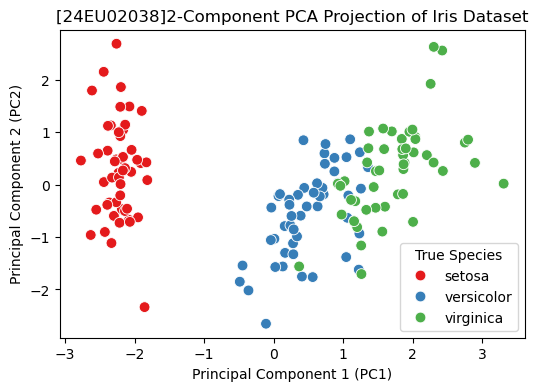

In [37]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=pca_df, x='PC_1', y='PC2', hue='species_name', palette='Set1', s=60)
plt.title("[24EU02038]2-Component PCA Projection of Iris Dataset")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend(title='True Species')
plt.show()

In [ ]:
Subtask 1.5: Analyzing Explained Variance Ratio

In [38]:
explained_variance = pca_model.explained_variance_ratio_

In [39]:
cumulative_variance = np.sum(explained_variance)

In [40]:
print("Explained Variance per Component:")

Explained Variance per Component:


In [41]:
for i, var in enumerate(explained_variance):
    print(f"  PC{i+1}: {var*100:.2f}%")

  PC1: 72.96%
  PC2: 22.85%


In [42]:
print(f"\nTotal Cumulative Variance Retained by 2 Components: {cumulative_variance*100:.2f}%")


Total Cumulative Variance Retained by 2 Components: 95.81%


In [ ]:
Task 2: Design clustering models using K-Means clustering for pattern discovery and data grouping

In [ ]:
Subtask 2.1: Determining Clusters via the Elbow Method (WCSS)

In [49]:
import warnings

In [50]:
warnings.filterwarnings("ignore")


In [51]:
from sklearn.cluster import KMeans

In [52]:
import matplotlib.pyplot as plt

In [53]:
wcss = []

In [54]:
k_range = range(1, 11)

In [55]:
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

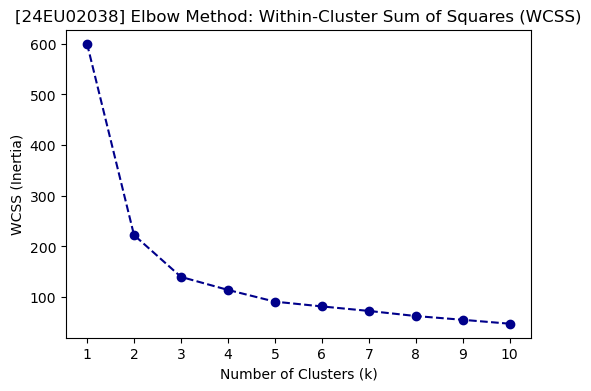

In [56]:
plt.figure(figsize=(6, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='darkblue')
plt.title("[24EU02038] Elbow Method: Within-Cluster Sum of Squares (WCSS)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(k_range)
plt.show()

In [ ]:
Subtask 2.2: Validating Optimal Clusters with Silhouette Analysis

In [57]:
from sklearn.metrics import silhouette_score

In [58]:
silhouette_scores = []

In [59]:
k_eval = range(2, 6)

In [60]:
for k in k_eval:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_temp)
    silhouette_scores.append(score)

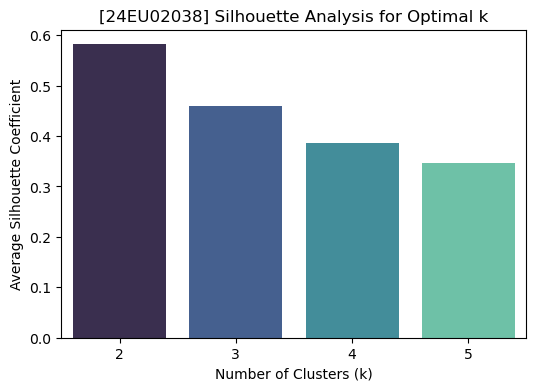

In [61]:
plt.figure(figsize=(6, 4))
sns.barplot(x=list(k_eval), y=silhouette_scores, palette='mako')
plt.title("[24EU02038] Silhouette Analysis for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Average Silhouette Coefficient")
plt.show()

In [62]:
best_k = k_eval[np.argmax(silhouette_scores)]

In [63]:
print(f"k = {best_k} yielded the highest silhouette coefficient ({max(silhouette_scores):.4f}).")

k = 2 yielded the highest silhouette coefficient (0.5818).


In [ ]:
Subtask 2.3: Implementing K-Means Clustering on the Raw Feature Space

In [67]:
kmeans_raw = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)

In [68]:
kmeans_raw_labels = kmeans_raw.fit_predict(X_scaled)

In [69]:
iris_df['cluster_raw'] = kmeans_raw_labels

In [70]:
print("K-Means clustering complete. First 5 sample allocations:")

K-Means clustering complete. First 5 sample allocations:


In [71]:
print(iris_df[['species_name', 'cluster_raw']].head(5))

  species_name  cluster_raw
0       setosa            1
1       setosa            1
2       setosa            1
3       setosa            1
4       setosa            1


In [ ]:
Subtask 2.4: Extracting and Inspecting Cluster Centroids

In [72]:
raw_centroids_scaled = kmeans_raw.cluster_centers_

In [73]:
raw_centroids_physical = scaler.inverse_transform(raw_centroids_scaled)

In [74]:
centroids_df = pd.DataFrame(data=raw_centroids_physical, columns=features)

In [75]:
centroids_df.index = [f"Cluster_{i}" for i in range(3)]

In [76]:
print("--- Estimated Cluster Centroids (Original Physical Units - cm) ---")

--- Estimated Cluster Centroids (Original Physical Units - cm) ---


In [77]:
print(centroids_df)

           sepal length (cm)  sepal width (cm)  petal length (cm)  \
Cluster_0           5.801887          2.673585           4.369811   
Cluster_1           5.006000          3.428000           1.462000   
Cluster_2           6.780851          3.095745           5.510638   

           petal width (cm)  
Cluster_0          1.413208  
Cluster_1          0.246000  
Cluster_2          1.972340  


In [ ]:
Subtask 2.5: Visualizing Raw Clusters and Centroids

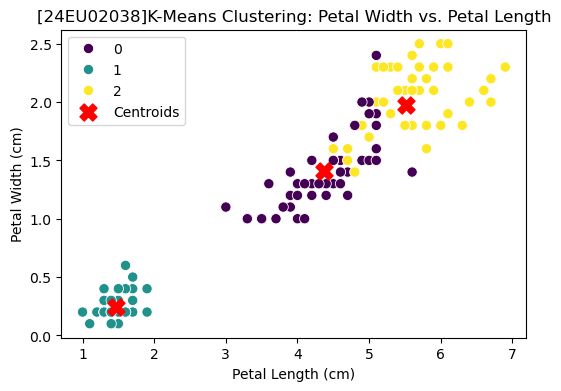

In [85]:
plt.figure(figsize=(6, 4))

# Convert standardized centroids to original units for plotting
raw_data = scaler.inverse_transform(X_scaled)

# Plot the continuous data points colored by cluster assignment
sns.scatterplot(x=raw_data[:, 2], y=raw_data[:, 3], hue=kmeans_raw_labels, palette='viridis', s=55, legend='full')

# Plot the calculated centroids on the same canvas
plt.scatter(
    raw_centroids_physical[:, 2], 
    raw_centroids_physical[:, 3], 
    color='red', 
    marker='X', 
    s=150, 
    label='Centroids'
)

plt.title("[24EU02038]K-Means Clustering: Petal Width vs. Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.show()


In [ ]:
Task 3: Analyze clustering performance and compare transformed feature spaces for improved data interpretation

In [ ]:
Subtask 3.1: K-Means Clustering in the PCA-Reduced Space

In [86]:
import warnings

In [87]:
warnings.filterwarnings("ignore")


In [88]:
from sklearn.cluster import KMeans

In [89]:
kmeans_pca = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)

In [90]:
kmeans_pca_labels = kmeans_pca.fit_predict(X_pca)

In [91]:
iris_df['cluster_pca'] = kmeans_pca_labels

In [92]:
print("PCA space K-Means clustering completed successfully.")

PCA space K-Means clustering completed successfully.


In [ ]:
Subtask 3.2: Internal Validation Metrics (Silhouette and Calinski-Harabasz Scores)

In [94]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score

In [95]:
sil_raw = silhouette_score(X_scaled, kmeans_raw_labels)

In [96]:
ch_raw = calinski_harabasz_score(X_scaled, kmeans_raw_labels)

In [97]:
sil_pca = silhouette_score(X_pca, kmeans_pca_labels)

In [98]:
ch_pca = calinski_harabasz_score(X_pca, kmeans_pca_labels)

In [99]:
print("--- Internal Validation (Unsupervised Quality Metrics) ---")

--- Internal Validation (Unsupervised Quality Metrics) ---


In [100]:
print(f"Raw 4D Feature Space  -> Silhouette Score: {sil_raw:.4f} | Calinski-Harabasz: {ch_raw:.2f}")

Raw 4D Feature Space  -> Silhouette Score: 0.4599 | Calinski-Harabasz: 241.90


In [101]:
print(f"PCA 2D Reduced Space -> Silhouette Score: {sil_pca:.4f} | Calinski-Harabasz: {ch_pca:.2f}")

PCA 2D Reduced Space -> Silhouette Score: 0.5092 | Calinski-Harabasz: 293.86


In [ ]:
Subtask 3.3: Faceted Visual Comparison: K-Means Clusters vs. True Species

In [103]:
import matplotlib.pyplot as plt

In [104]:
import seaborn as sns

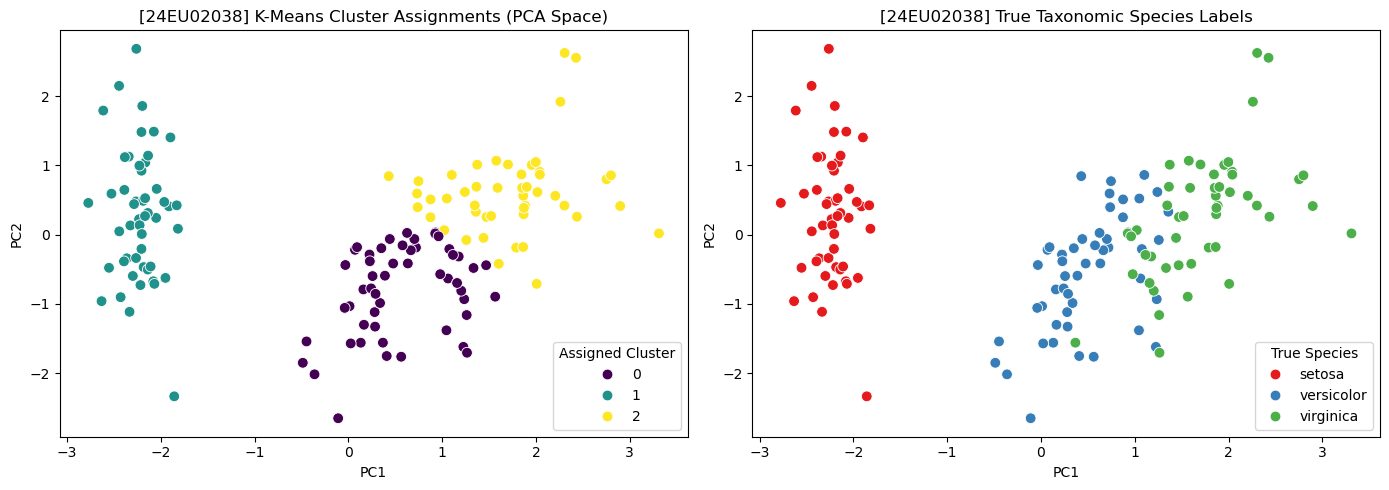

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: PCA Coordinates colored by K-Means cluster allocations
sns.scatterplot(
    data=pca_df, x='PC_1', y='PC2', hue=kmeans_pca_labels, 
    palette='viridis', s=60, ax=axes[0]
)
axes[0].set_title("[24EU02038] K-Means Cluster Assignments (PCA Space)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(title='Assigned Cluster')

# Plot 2: PCA Coordinates colored by true species labels
sns.scatterplot(
    data=pca_df, x='PC_1', y='PC2', hue='species_name', 
    palette='Set1', s=60, ax=axes[1]
)
axes[1].set_title("[24EU02038] True Taxonomic Species Labels")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(title='True Species')

plt.tight_layout()
plt.show()